# 02 · Streaming: replay dữ liệu thật qua một event bus

Notebook này mô phỏng luồng dữ liệu thời gian thực bằng cách phát lại dữ liệu lịch sử theo micro-batch. Nó chứng minh ba cơ chế quan trọng:

1. **Throughput** khi dữ liệu đến liên tục.
2. **Deduplication** theo `(location_id, event_time)`.
3. **Watermark** cho bản ghi đến muộn.

> **Engine lite:** file-based event bus thay cho Kafka. Producer ghi JSONL vào `stream/landing/`; consumer đọc các file mới và ghi vào DuckDB. Message schema giữ nguyên như một Kafka topic thật.


In [1]:
import sys, shutil
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from config import *
ensure_dirs()
setup_matplotlib()

import duckdb
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from warehouse import connect, create_base_tables
from streaming import (
    init_stream_tables, produce_batches, make_late_batch, make_time_batch,
    ingest_file, process_new_files, stream_summary,
)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)


## 1. Chuẩn bị bảng streaming

Tạo lại các bảng stream để notebook có thể chạy lặp lại. Bảng `fact_weather_hourly` dùng làm nguồn replay nếu chưa có.


In [2]:
con = connect()
tables = {row[0] for row in con.execute("SHOW TABLES").fetchall()}
if "fact_weather_hourly" not in tables:
    create_base_tables(con)

for table in ("fact_weather_stream", "stream_ingest_log", "stream_processed_files"):
    con.execute(f"DROP TABLE IF EXISTS {table}")
init_stream_tables(con)
print("stream tables ready")


stream tables ready


## 2. Producer: chia 100.000 dòng thành 20 micro-batch

Mỗi file JSONL là một micro-batch 5.000 dòng. Trong Kafka thật, producer sẽ gửi từng message; ở đây cả batch được ghi thành một file để dễ quan sát.


In [3]:
landing = STREAM_DIR / "landing"
files = produce_batches(CSV_HOURLY, landing, batch_size=5_000, max_rows=100_000)
display(pd.DataFrame({
    "batch": [f.name for f in files[:5]],
    "kb": [round(f.stat().st_size / 1024, 1) for f in files[:5]],
}))
print(f"{len(files)} batches · {sum(1 for _ in landing.glob('*.jsonl'))} files")


,batch,kb
0,batch_00000.jsonl,860.3
1,batch_00001.jsonl,860.6
2,batch_00002.jsonl,860.3
3,batch_00003.jsonl,860.6
4,batch_00004.jsonl,860.5


20 batches · 20 files


## 3. Consumer: ingest và đo throughput

Consumer xử lý từng file mới, chèn vào `fact_weather_stream`, bỏ qua bản ghi đã tồn tại. `delay=0.05` giây mô phỏng nhịp đến giữa các batch.


In [4]:
metrics = process_new_files(con, landing, delay=0.05)
display(metrics.head(8).style.format({"seconds": "{:.4f}"}))
display(stream_summary(con))


,file,rows,table_rows,late,seconds
0,batch_00000.jsonl,5000,5000,0,0.0439
1,batch_00001.jsonl,5000,10000,0,0.0510
2,batch_00002.jsonl,5000,15000,0,0.1112
3,batch_00003.jsonl,5000,20000,0,0.0552
4,batch_00004.jsonl,5000,25000,0,0.0671
5,batch_00005.jsonl,5000,30000,0,0.0565
6,batch_00006.jsonl,5000,35000,0,0.0716
7,batch_00007.jsonl,5000,40000,0,0.0645


,rows,locations,min_time,max_time,late_rows,duplicate_rows
0,100000,12,2015-01-01,2024-12-31 21:00:00,0.0,0


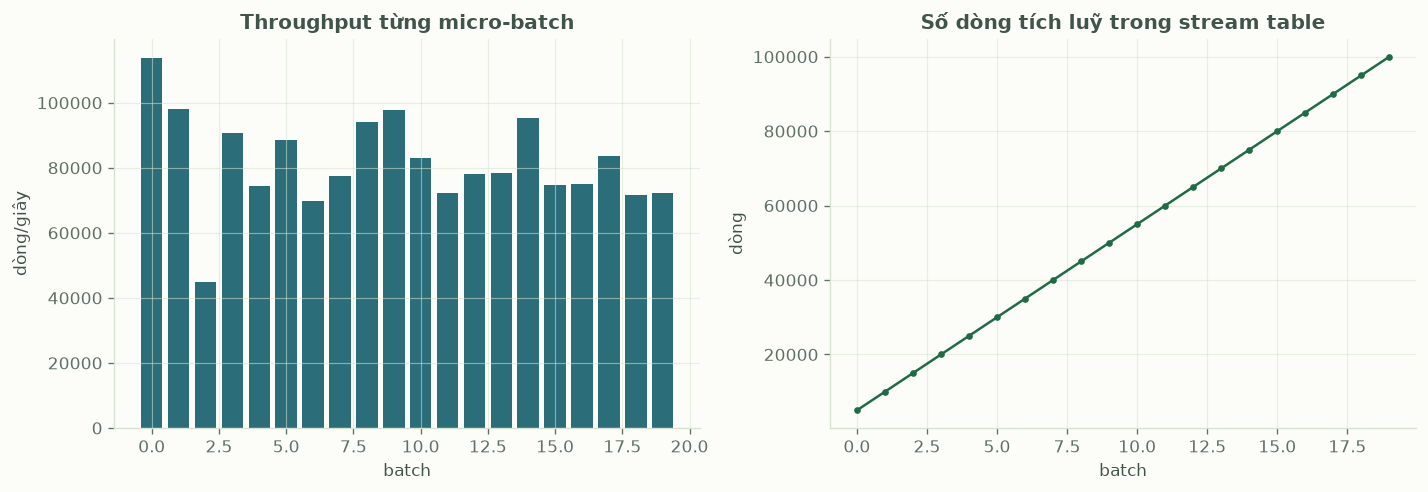

In [5]:
metrics["rows_per_sec"] = metrics["rows"] / metrics["seconds"].clip(lower=1e-9)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].bar(range(len(metrics)), metrics["rows_per_sec"], color=PALETTE["teal"])
axes[0].set_title("Throughput từng micro-batch")
axes[0].set_xlabel("batch")
axes[0].set_ylabel("dòng/giây")
axes[1].plot(range(len(metrics)), metrics["table_rows"], color=PALETTE["green"], marker="o", markersize=3)
axes[1].set_title("Số dòng tích luỹ trong stream table")
axes[1].set_xlabel("batch")
axes[1].set_ylabel("dòng")
fig.tight_layout()
save_figure(fig, "02_stream_throughput.png")
plt.show()


## 4. Thử duplicate

Sao chép một batch đã xử lý thành file mới. Consumer sẽ đọc file mới nhưng `NOT EXISTS` chặn các bản ghi trùng; số dòng trong bảng không tăng.


In [6]:
src = sorted(landing.glob("batch_*.jsonl"))[0]
dst = landing / "duplicate_batch.jsonl"
shutil.copyfile(src, dst)
dup = ingest_file(con, dst)
display(pd.DataFrame([dup]).style.format({"seconds": "{:.4f}"}))
display(stream_summary(con))


,file,rows,table_rows,late,seconds
0,duplicate_batch.jsonl,5000,100000,5000,0.0460


,rows,locations,min_time,max_time,late_rows,duplicate_rows
0,100000,12,2015-01-01,2024-12-31 21:00:00,0.0,0


## 5. Thử dữ liệu đến muộn

Để phép thử rõ ràng, stream table được xoá và nạp lại một batch "hiện tại" từ 2024, sau đó nạp một batch cũ từ 2015. Với watermark 10 phút, batch cũ bị đánh dấu `is_late=True`; dữ liệu vẫn được giữ để kiểm toán nhưng không được coi là dữ liệu实时 hợp lệ.


In [7]:
# Xoá stream để tách riêng phép thử watermark khỏi 100.000 dòng phía trên.
con.execute("DELETE FROM fact_weather_stream")

# 1) Nạp một batch "hiện tại" từ 2024.
current_path = make_time_batch(
    CSV_HOURLY, landing, "2024-01-01", "2024-01-02",
    n=5_000, name="current_batch.jsonl"
)
ingest_file(con, current_path)

# 2) Nạp batch cũ từ 2015; watermark phải đánh dấu đây là dữ liệu muộn.
late_path = make_late_batch(CSV_HOURLY, landing, n=200)
late = ingest_file(con, late_path)
display(pd.DataFrame([late]).style.format({"seconds": "{:.4f}"}))
display(con.execute(
    "SELECT is_late, COUNT(*) AS rows FROM fact_weather_stream GROUP BY 1 ORDER BY 1"
).df())


,file,rows,table_rows,late,seconds
0,late_batch.jsonl,200,488,200,0.0373


,is_late,rows
0,False,288
1,True,200


## 6. Xem dữ liệu mới nhất trong stream table


In [8]:
display(con.execute(
    """
    SELECT event_time, location_id, t2m_c, soil_wetness_root, is_late
    FROM fact_weather_stream
    ORDER BY event_time DESC
    LIMIT 8
    """
).df())


,event_time,location_id,t2m_c,soil_wetness_root,is_late
0,2024-01-01 23:00:00,US-IA,-3.63,0.43,False
1,2024-01-01 23:00:00,US-KS,-1.99,0.31,False
2,2024-01-01 23:00:00,KE-NKR,14.26,0.65,False
3,2024-01-01 23:00:00,BR-PR,22.77,0.69,False
4,2024-01-01 23:00:00,MA-MEK,10.13,0.55,False
5,2024-01-01 23:00:00,IN-PB,7.79,0.45,False
6,2024-01-01 23:00:00,VN-HD,18.60,0.66,False
7,2024-01-01 23:00:00,VN-CT,23.97,0.76,False


## Ánh xạ sang Kafka thật

| Thành phần trong notebook | Kafka/Spark tương đương |
|---|---|
| `produce_batches()` ghi JSONL | Kafka producer gửi message vào topic |
| `stream/landing/` | Kafka topic `agri.weather.hourly` |
| `process_new_files()` | Spark Structured Streaming `readStream.format("kafka")` |
| `stream_processed_files` | checkpoint + offset |
| `NOT EXISTS (location, time)` | `dropDuplicates` / idempotent sink |
| `is_late` + cutoff 10 phút | watermark + allowed lateness |
| `stream_ingest_log` | Kafka lag / Spark progress metrics |

Khi có Docker, có thể thay producer/consumer bằng Kafka + Spark mà không đổi schema message.


## Kết luận notebook 02

- 100.000 dòng đã đi qua event bus mô phỏng và vào `fact_weather_stream`.
- Throughput và số dòng tích luỹ được lưu trong `reports/02_stream_throughput.png`.
- Duplicate không làm tăng số dòng; bản ghi muộn được đánh dấu thay vì âm thầm ghi đè.
- Đây là mô phỏng ở mức dữ liệu, không phải kiểm thử node Kafka thật. Phần fault test thật nằm trong notebook 04.


In [9]:
con.close()
